# 23 · Vocational Higher Secondary (VHSE) batches per school — VHSCAP 2026 (Kerala)

**Why:** Kerala's Vocational Higher Secondary schools (Plus One / Plus Two, NSQF job-role courses) also serve the
16–17 age group. Their places are counted with the Plus One / Plus Two seats (notebook 22) in the higher-secondary
capacity.

**Source:** VHSCAP — Higher Secondary (Vocational) single-window admission, Directorate of General Education (VHSE
wing), Government of Kerala, `https://www.vhscap.kerala.gov.in/vhse_cms/` (public downloads):
- **Annexure 1, School Course List 2026:** every VHSE school (6-digit VHSE code) with **one entry per batch**
  (e.g. `GFT (28)` listed twice = two batches of course 28, General Fitness Trainer);
- **Prospectus 2026** (approved by G.O.(Rt) No. 3537/2026/GEDN, 25-05-2026), section 21 "ബാച്ചും എണ്ണവും"
  (page 12): **30 students per batch**; a batch needs at least 15 students to continue.

**Link to our schools:** the "VHSE Code" on the Sametham school pages (`sam_vhse_code`) is the same 6-digit code.

**Output:** raw PDFs in `data/raw/vhscap/`; one row per batch → `data/interim/schools/vhscap_vhse_batches.csv`.
Notebook 09 adds the batches and seats to `FINAL COMPLETE DATASET/schools/kerala_schools_capacity.csv`.

## Project folder (laptop or Colab)

In [1]:
# Project folder. Laptop: open the notebook from "PROJECTS IPYNB" (or the project root).
# Google Colab: upload the project folder to Google Drive ("My Drive") and set its name below.
from pathlib import Path
import sys
PROJECT_FOLDER = "Distance-Capacity-and-Inequality-in-Access-to-Government-and-Aided-Schools"  # Colab only: folder name inside My Drive
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive") / PROJECT_FOLDER
else:
    PROJECT = Path.cwd().parent if Path.cwd().name in ("notebooks", "PROJECTS IPYNB") else Path.cwd()
assert (PROJECT / "scripts").is_dir(), f"project folder not found: {PROJECT}"
sys.path.insert(0, str(PROJECT / "scripts"))

In [2]:
# Colab only: install packages that Colab does not have by default (does nothing on the laptop)
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rapidfuzz", "pymupdf", "pyogrio", "rasterio"], check=True)

## Imports and settings

In [3]:
import re
import time

import pandas as pd
import pymupdf
import requests
import urllib3.util.connection

urllib3.util.connection.HAS_IPV6 = False  # IPv6 times out from this network (see notebook 14)
RAW = PROJECT / "data" / "raw" / "vhscap"
OUT = PROJECT / "data" / "interim" / "schools" / "vhscap_vhse_batches.csv"
BASE = "https://www.vhscap.kerala.gov.in/vhse_control/admin/uploads/cms/"
FILES = {"annexure1_school_course_list_2026.pdf": "20260525152737.pdf",   # Annexure 1: School Course List
         "prospectus_vhse_2026.pdf": "20260525155659.pdf"}               # Higher Secondary Vocational NSQF Prospectus 2026
HEADERS = {"User-Agent": "msc-spatial-inequality-study/0.1 (academic project)"}
SEATS_PER_BATCH = 30  # prospectus 2026, section 21 "ബാച്ചും എണ്ണവും" (page 12): 30 students per batch

## Download the two PDFs (once)

In [4]:
RAW.mkdir(parents=True, exist_ok=True)
for name, remote in FILES.items():
    f = RAW / name
    if not f.exists():
        r = requests.get(BASE + remote, headers=HEADERS, timeout=120)
        r.raise_for_status()
        f.write_bytes(r.content)
        time.sleep(2)
    print(f"{name}: {f.stat().st_size / 1e6:.1f} MB")

annexure1_school_course_list_2026.pdf: 0.8 MB


prospectus_vhse_2026.pdf: 1.8 MB


## The seat rule (prospectus, section 21)

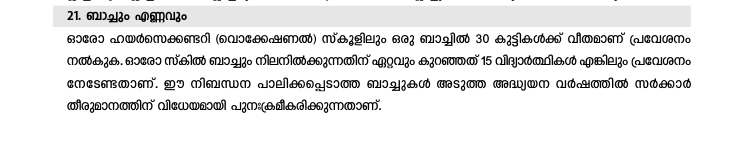

Section 21: each VHSE batch admits 30 students; a batch needs at least 15 students to continue.


In [5]:
# The seat rule, shown from the prospectus itself (Malayalam; the page is rendered so it can be read in the notebook)
from IPython.display import Image, display

page = pymupdf.open(RAW / "prospectus_vhse_2026.pdf")[15]  # printed page 12, section 21
display(Image(page.get_pixmap(dpi=90, clip=pymupdf.Rect(0, page.rect.height * 0.80, page.rect.width, page.rect.height * 0.95)).tobytes("png")))
print("Section 21: each VHSE batch admits 30 students; a batch needs at least 15 students to continue.")

## Parse Annexure 1: one row per batch

In [6]:
def parse_annexure(pdf):
    """Annexure 1 lists each school as '<6-digit code> <name>' (the code is sometimes alone on its line, the name on the
    next) followed by one 'ABBR (NN)' entry per batch, e.g. 'GFT (28)' twice = two batches of course 28."""
    lines = [l.strip() for page in pymupdf.open(pdf) for l in page.get_text().split("\n")]
    rows, school, region, i = [], None, None, 0
    while i < len(lines):
        l = lines[i]
        if re.fullmatch(r"[A-Za-z ]+Region", l):
            region = l
        elif m := re.match(r"^(9\d{5})(?:\s+(.+))?$", l):
            name = m.group(2) or lines[i + 1]
            i += 0 if m.group(2) else 1
            school = (m.group(1), name.strip(), region)
        else:
            for abbr, code in re.findall(r"\b([A-Z]{2,6})\s*\((\d{2})\)", l):
                assert school, f"batch before any school: {l}"
                rows.append({"vhse_code": school[0], "school_name": school[1], "region": school[2],
                             "course_abbr": abbr, "course_code": int(code)})
        i += 1
    return pd.DataFrame(rows)


batches = parse_annexure(RAW / "annexure1_school_course_list_2026.pdf")
assert batches["vhse_code"].str.fullmatch(r"9\d{5}").all()
OUT.parent.mkdir(parents=True, exist_ok=True)
batches.to_csv(OUT, index=False, encoding="utf-8")
per_school = batches.groupby("vhse_code").size()
print(f"written {OUT}: {per_school.size} schools, {len(batches)} batches "
      f"-> {len(batches) * SEATS_PER_BATCH:,} seats per year at {SEATS_PER_BATCH} per batch")
print("batches per school (how often):", per_school.value_counts().sort_index().to_dict())
print("schools per region:", batches.drop_duplicates("vhse_code")["region"].value_counts().to_dict())

written C:\Users\ASUS\Desktop\sem3\BIG SPATIAL DATA\PROJECT- SPATIAL INEQUALITY ASESSMENT\data\interim\schools\vhscap_vhse_batches.csv: 389 schools, 1101 batches -> 33,030 seats per year at 30 per batch
batches per school (how often): {1: 5, 2: 195, 3: 96, 4: 59, 5: 22, 6: 12}
schools per region: {'Kollam Region': 93, 'Ernakulam Region': 65, 'Thrissur Region': 52, 'Kuttippuram Region': 52, 'Chengannur Region': 48, 'Payyannur Region': 41, 'Vadakara Region': 38}
